<div style="background: linear-gradient(120deg, #3b1e54 0%, #8a2a6b 62%, #d6336c 100%); color: #ffffff; padding: 30px 34px; border-radius: 14px; margin: 4px 0 10px 0;">
<div style="font-size: 0.8em; letter-spacing: 0.16em; text-transform: uppercase; opacity: 0.85;">Statistical Methods · GSSI · Lecture 1 · 12/11</div>
<div style="font-size: 2.7em; font-weight: 800; line-height: 1.1; margin: 10px 0 8px 0;">Probability</div>
<div style="font-size: 1.15em; opacity: 0.95;">The language we use to put numbers on what we don't know.</div>
</div>

**Reading** · G. Benato, *Statistical Methods for Astroparticle Physics* (GSSI lecture notes), chapters 1-2 · D. Gerosa, [*Astrostatistics and Machine Learning*](https://github.com/dgerosa/astrostatistics_bicocca_2025) (Milano-Bicocca 2025), lectures 2-4, which inspired some of the examples marked ↗ *Extra*.

**In this lecture**

1. [Speaking the same language](#s1)
2. [What is probability?](#s2)
3. [The rules of the game](#s3)
4. [Bayes' theorem](#s4)
5. [Random variables and PDFs](#s5)
6. [Changing variables](#s6)
7. [Summarizing a distribution](#s7)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats

# --- house style: one palette for every figure ------------------------------------
PLUM, FUCHSIA, TEAL, AMBER, GREY = "#3b1e54", "#d6336c", "#0b7285", "#e8890c", "#6b7280"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.prop_cycle": cycler(color=[FUCHSIA, PLUM, TEAL, AMBER]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": "#2a1a3a", "text.color": "#2a1a3a",
    "xtick.color": GREY, "ytick.color": GREY, "lines.linewidth": 2.0,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10,
})
rng = np.random.default_rng(2026)   # fixed seed: every run gives the same figures

---
## 1. Speaking the same language <a id="s1"></a>

Physicists and statisticians often use different words for the same thing. Let's fix the vocabulary before the formulas.

| Symbol | Meaning |
|:--|:--|
| Greek letters $\theta, \mu, \sigma$ | parameters |
| Roman letters $x, y$ | random variables |
| Capital $P, F$ | probability distribution, cumulative distribution |
| Lowercase $p, f$ | probability density function (PDF) |
| Bar $\bar{x}$ | average value |
| Hat $\hat{\theta}, \hat{\mu}$ | estimate of a parameter |

| Physicists say | Statisticians say | | Demographic language | Physics language |
|:--|:--|:-:|:--|:--|
| determine | estimate | | sample | data(set) |
| estimate | guess | | draw a sample | observe, measure |
| | | | sample of size $N$ | $N$ observations |
| | | | population | observable space |

Think of a census or an election poll: we must tell the properties of the **sample** apart from those of the underlying **population**. So we say *"parent mean = population mean = mean of the underlying distribution"*, or *"sample mean"*.

<div style="border-left: 6px solid #e8890c; background: #fff3dc; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**▲ Watch out**

Avoid misleading terms. **Error** → variance, confidence interval, interval estimate, credible interval. **Propagation of error** → change of variable.

</div>

There are two philosophies. The **Bayesian** approach measures the *degree of belief* that a statement is true; the **frequentist** (or classical) approach measures the *relative frequency* of something happening. They differ in what they can be applied to:

| | Bayesian | Frequentist |
|:--|:-:|:-:|
| Statement depends on the observer | ✓ | |
| Applies to repeatable cases | ✓ | ✓ |
| Applies to future unknown facts | ✓ | |
| Applies to past unknown facts | ✓ | |
| Applies to the possible outcome of an experiment | ✓ | ✓ |
| Applies to the true value of a parameter | ✓ | |
| Allows goodness-of-fit (single hypothesis testing) | | ✓ |
| Allows decision theory | ✓ | |

---
## 2. What is probability? <a id="s2"></a>

An **event** is a random variable that can take the values 0 or 1. A **composite event** is a set of elementary events: it occurs when any of its elementary events $x_i \in A$ occurs, so $P(A) = P(\text{any } x_i \in A \text{ occurs})$.

### Mathematical probability

$\Omega$ is the set of all the elementary events $x_i$, which are mutually exclusive. We call *probability* everything that obeys the Kolmogorov axioms (1933):

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Kolmogorov axioms**

$$P(x_i) \ge 0 \quad \forall i, \qquad P(x_i \lor x_j) = P(x_i) + P(x_j) \quad (i \ne j), \qquad \sum_i P(x_i) = 1$$

The definition is abstract: **any** quantity that satisfies the axioms is a probability.

</div>

### Frequentist probability

Run an experiment that measures $N$ events, and suppose $K$ of them are of type $X$:

$$P(x) = \lim_{N \to \infty} \frac{K}{N} = \lim_{N\to\infty}\frac{\text{number of favorable cases}}{\text{number of possible cases}}$$

It applies only to **repeatable** events. In principle we need $N = \infty$, but often the limit can be computed analytically, or numerically to great precision. Exact repeatability is impossible anyway, so it is the physicist's job to make sure all relevant conditions are repeatable, or to correct for them. And no: it cannot predict whether Italy will win the next World Cup.

Let's watch the limit happen. Five runs of coin tosses, with $p = 0.5$:

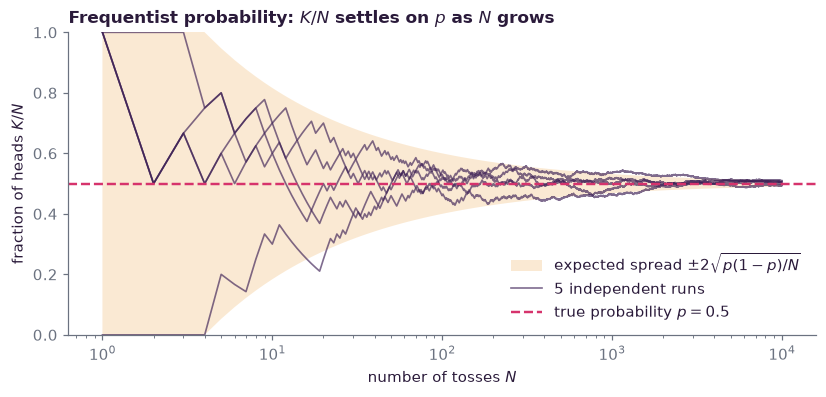

In [2]:
p_true, n_tosses, n_runs = 0.5, 10_000, 5
N = np.arange(1, n_tosses + 1)

fig, ax = plt.subplots(figsize=(7.4, 3.5), constrained_layout=True)
spread = 2 * np.sqrt(p_true * (1 - p_true) / N)                        # expected fluctuation of K/N
ax.fill_between(N, p_true - spread, p_true + spread, color=AMBER, alpha=0.18, lw=0,
                label=r"expected spread $\pm 2\sqrt{p(1-p)/N}$")
for i in range(n_runs):
    running = np.cumsum(rng.random(n_tosses) < p_true) / N              # K/N after N tosses
    ax.plot(N, running, color=PLUM, lw=1.1, alpha=0.65, label=f"{n_runs} independent runs" if i == 0 else None)
ax.axhline(p_true, color=FUCHSIA, lw=1.6, ls="--", label=r"true probability $p = 0.5$")
ax.set(xscale="log", ylim=(0, 1), xlabel="number of tosses $N$", ylabel=r"fraction of heads $K/N$")
ax.set_title(r"Frequentist probability: $K/N$ settles on $p$ as $N$ grows", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

### Bayesian probability (the coherent bet)

The **degree of belief** is the amount $F(x)$ I am willing to bet that $X$ will occur, knowing that if I win I get a fixed amount $K$:

$$P(x) = \frac{F(x)}{K} \qquad \begin{cases} P(x) = 0 & \text{if I am sure } X \text{ won't happen} \\ 0 < P(x) < 1 & \text{otherwise} \\ P(x) = 1 & \text{if I am sure } X \text{ will happen} \end{cases}$$

Note that still $\sum_i P(x_i) = 1$. This probability belongs to the system **and** to the observer: it depends on what the observer knows, and it changes when that knowledge improves. In exchange, it can be applied to non-repeatable phenomena and to the **true value of a parameter** of a physics theory.

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Choose the tool by the question**

Which probability to use depends on the question you ask. It matters because the parameters of a theory are fixed by Nature, but unknown to us:

- Given a measurement, what is the true value of a parameter of the theory?
- Given a measurement, what interval contains the true (unknown) value with a given probability?
- Is my parameterization of the data good enough, or does it hint at *new physics*?
- Which of two alternative models describes the data better?
- Given previous experiments, what is the expected outcome of a future one?

</div>

---
## 3. The rules of the game <a id="s3"></a>

**Addition law.** For two non-exclusive sets $A, B$ of events:

$$P(A \lor B) = P(A) + P(B) - P(A \land B)$$

**Conditional probability.** The probability that an elementary event, known to belong to $B$, is also in $A$:

$$P(A \land B) = P(A|B)\,P(B) = P(B|A)\,P(A) \quad\Longrightarrow\quad P(A|B) = \frac{P(A \land B)}{P(B)}$$

**Independence.** $A$ and $B$ are independent if $P(A|B) = P(A)$: the occurrence of $B$ is irrelevant for $A$. Equivalently, $P(A \land B) = P(A)\,P(B)$.

**Law of total probability.** Let $E_1, \dots, E_N$ be a partition of a set $E$, and let $A_1, \dots, A_N$ be a disjoint partition of the sample space $\Omega$ such that $E_i = E \land A_i$. Then $P(E_i) = P(E|A_i)\,P(A_i)$ and

$$P(E) = \sum_{i=1}^{N} P(E|A_i)\,P(A_i)$$

It can be read as the weighted average of the probabilities $P(A_i)$ with weights $w_i = P(E|A_i)$.

---
## 4. Bayes' theorem <a id="s4"></a>

Write the joint probability of two sets of events in both orders, $P(A \land B) = P(A)\,P(B|A) = P(B)\,P(A|B)$, and divide:

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Bayes' theorem**

$$P(A|B) = \frac{P(B|A)\,P(A)}{P(B)} \qquad\qquad P(A_i|B) = \frac{P(B|A_i)\,P(A_i)}{\sum_j P(B|A_j)\,P(A_j)}$$

The second form holds for $N$ exclusive and exhaustive sets $A_i$ and any event $B$. $P(A_i)$ is the **prior**, $P(A_i|B)$ the **posterior**.

</div>

**Example.** I have a detector and I want to measure a proton.

- $P(B)$ = probability of any particle triggering an event
- $P(A)$ = probability of a proton hitting the detector
- $P(B|A)$ = probability of a proton giving a triggered event
- $P(A|B)$ = probability of a triggered event to be induced by a proton

In physics we compare **hypotheses**. $H_0$ = *background only* (known physics only); $H_1$ = *signal + background* (known physics + new physics). Both depend on parameters $\vec\theta \in \Omega$ (some can be in common), and we measure data $\vec{x}$.

### Parameter estimation

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Bayes for parameter estimation**

$$P(\vec\theta|\vec x) = \frac{P(\vec x|\vec\theta)\,\pi(\vec\theta)}{\int_\Omega P(\vec x|\vec\theta)\,\pi(\vec\theta)\,d\vec\theta}$$

$P(\vec x|\vec\theta)$ is the **likelihood**, $\pi(\vec\theta)$ the **prior**, the denominator a normalization constant, and $P(\vec\theta|\vec x)$ the **posterior** of the parameters after measuring the data.

</div>

### Hypothesis testing

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Bayes for hypothesis testing**

$$P(H_i|\vec x) = \frac{P(\vec x|H_i)\,\pi(H_i)}{\sum_j P(\vec x|H_j)\,\pi(H_j)} \qquad\qquad P(\vec x|H_i) = \int_\Omega P(\vec x|H_i,\vec\theta)\,\pi(\vec\theta)\,d\vec\theta$$

$\pi(H_i)$ is the prior probability of the hypothesis: this is the **subjective** part of the method.

</div>

### Example: when the prior refuses to move

Take a set of events $\{A_i\}$ and a prior $\pi(A_i) = 1$ if $i = 0$, and $0$ otherwise: we are *absolutely sure* that $A_0$ is true. We take a measurement and observe some event $B$. Then

- for $i \ne 0$: $\; P(A_i|B) = 0 = \pi(A_i)$
- for $i = 0$: $\; P(A_0|B) = \dfrac{P(B|A_0)}{\sum_i P(B|A_i)\,\pi(A_i)} = 1$ (provided $P(B|A_0) > 0$)

No matter what the data say, if I believe something with probability 1, I won't change my mind. That is a dogma, and it is the reason why the scientific method needs priors that the data are allowed to overrule.

<div style="border-left: 6px solid #0b7285; background: #e5f3f6; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**↗ Extra: the positive test**

A medical test is $99\%$ sensitive, $P(+|\text{disease}) = 0.99$, and gives a false positive in $5\%$ of healthy people. The disease affects $1\%$ of the population. You test positive. How worried should you be?

</div>

In [3]:
prior = 0.01     # P(disease)
sens  = 0.99     # P(+ | disease)
fpr   = 0.05     # P(+ | healthy)

p_positive = sens * prior + fpr * (1 - prior)            # law of total probability
posterior  = sens * prior / p_positive                    # Bayes' theorem
print(f"P(disease | +) = {posterior:.1%}")

P(disease | +) = 16.7%


Only about one positive in six is a true positive! The test is accurate, but the disease is rare: the **prior** matters as much as the likelihood.

---
## 5. Random variables and PDFs <a id="s5"></a>

A **random event** $X$ is an event with more than one possible outcome, to which a probability can be assigned. It corresponds to a **random variable** $x$. For a discrete variable, $\sum_i P(x_i) = 1$:

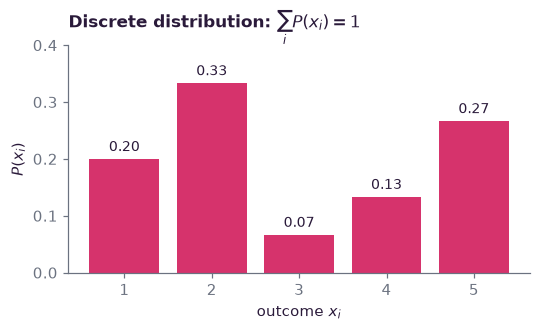

In [4]:
p = np.array([3, 5, 1, 2, 4]) / 15
fig, ax = plt.subplots(figsize=(4.8, 2.9), constrained_layout=True)
bars = ax.bar(range(1, 6), p, width=0.8)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in p], padding=3, color="#2a1a3a", fontsize=9)
ax.set(xlabel="outcome $x_i$", ylabel="$P(x_i)$", xticks=range(1, 6), ylim=(0, 0.4))
ax.set_title(fr"Discrete distribution: $\sum_i P(x_i) = {p.sum():.0f}$", loc="left")
plt.show()

A set of $N$ observations of $x$ can be seen as a **single** observation of the vector $\vec x = (x_1, \dots, x_N)$: this is exactly what a histogram is.

Independence extends from events to variables. Two variables are independent if their joint PDF factorizes into two **different** functions, the PDFs of $x$ and of $y$:

$$f(x, y) = f_x(x)\,f_y(y)$$

### Probability density function (PDF)

Take a sample space $\Omega \subseteq \mathbb{R}^n$. A measurement is an extraction from $\Omega$, i.e. a point $\vec x \in \Omega$, and we associate to each point a *probability density* $f(\vec x) \ge 0$. The probability of an event $A$ is

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ PDF**

$$P(A) = \int_A f(\vec x)\,d\vec x \qquad\qquad \int_\Omega f(\vec x)\,d\vec x = 1$$

$f(\vec x) = dP/d\vec x$ is the *differential* probability: the probability per unit area, volume, etc. In more than one dimension it is also called the **joint** probability distribution. A discrete variable fits in the same framework with Dirac deltas: $f(x) = \sum_i P_i\,\delta(x - x_i)$.

</div>

### Cumulative distribution

$$F(x) = \int_{-\infty}^{x} f(y)\,dy \qquad\Longrightarrow\qquad F(\tilde x) = P(x \le \tilde x)$$

$F$ increases monotonically from 0 to 1.

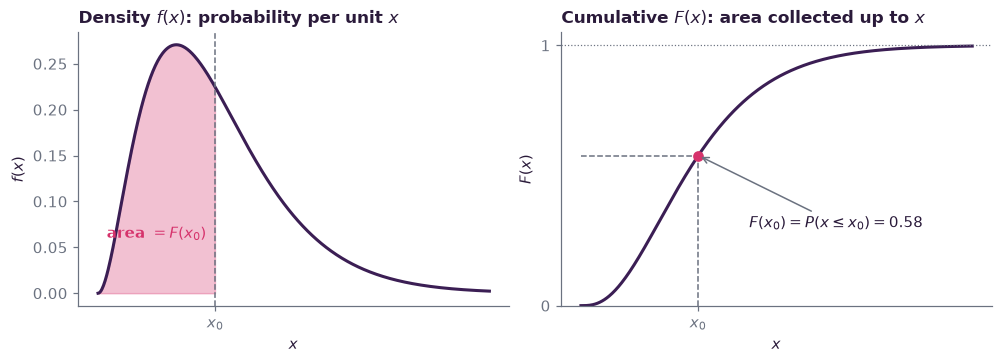

In [5]:
x = np.linspace(0, 10, 500)
d, x0 = stats.gamma(3.0), 3.0
fig, (axf, axF) = plt.subplots(1, 2, figsize=(9, 3.2), constrained_layout=True)

# left: the density, with the area up to x0 highlighted
axf.plot(x, d.pdf(x), color=PLUM)
axf.fill_between(x, d.pdf(x), where=x <= x0, color=FUCHSIA, alpha=0.3)
axf.axvline(x0, color=GREY, ls="--", lw=1)
axf.text(1.5, 0.06, r"area $= F(x_0)$", ha="center", color=FUCHSIA, fontweight="bold")
axf.set(xlabel="$x$", ylabel="$f(x)$", xticks=[x0], xticklabels=["$x_0$"])
axf.set_title("Density $f(x)$: probability per unit $x$", loc="left")

# right: the cumulative is that area, collected as x grows
axF.plot(x, d.cdf(x), color=PLUM)
axF.plot([x0, x0], [0, d.cdf(x0)], color=GREY, ls="--", lw=1)
axF.plot([0, x0], [d.cdf(x0)] * 2, color=GREY, ls="--", lw=1)
axF.plot(x0, d.cdf(x0), "o", color=FUCHSIA)
axF.axhline(1, color=GREY, lw=0.8, ls=":")
axF.annotate(fr"$F(x_0) = P(x \leq x_0) = {d.cdf(x0):.2f}$", xy=(x0, d.cdf(x0)), xytext=(4.3, 0.3),
             arrowprops=dict(arrowstyle="->", color=GREY), color="#2a1a3a")
axF.set(xlabel="$x$", ylabel="$F(x)$", xticks=[x0], xticklabels=["$x_0$"], yticks=[0, 1], ylim=(0, 1.05))
axF.set_title("Cumulative $F(x)$: area collected up to $x$", loc="left")
plt.show()

### Marginal and conditional distributions

Take $\vec x = (x_1, \dots, x_N)$ with PDF $f(\vec x)$. The **marginal** distribution of $x_i$ integrates over all the *other* variables, so the result has dimension 1:

$$f(x_i) = \int f(\vec x)\,dx_1 \cdots dx_{i-1}\,dx_{i+1} \cdots dx_N$$

Take now a 2D PDF $f(x, y)$ and fix $x = x_0$. The **conditional** distribution of $y$ is a slice of the joint PDF, renormalized:

$$f(y|x_0) = \frac{f(x_0, y)}{\int f(x_0, y')\,dy'}$$

consistent with $P(B|A) = P(A \land B)/P(A)$ for $A = \{x_0 < x < x_0 + \delta x\}$. Marginalizing *integrates*; conditioning *slices*.

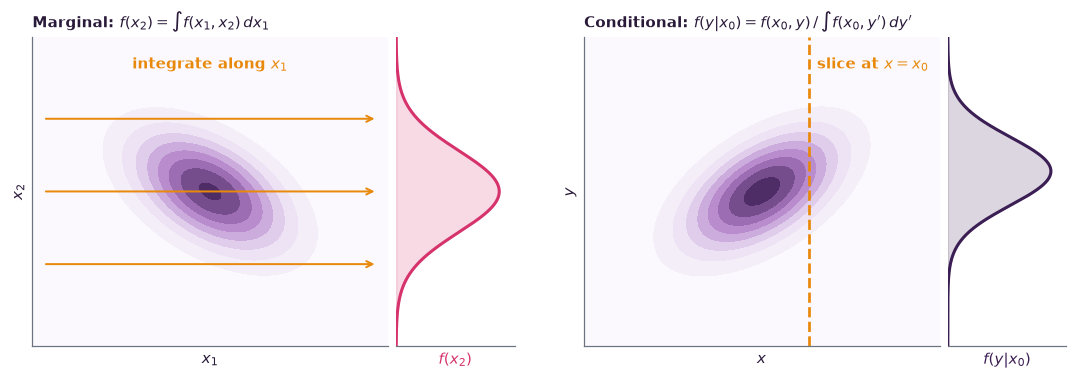

In [6]:
from matplotlib.colors import LinearSegmentedColormap
heat = LinearSegmentedColormap.from_list("plum_heat", ["#ffffff", "#e9ddf2", "#b07cc6", PLUM])

def joint(rho, sx=1.0, sy=0.9, lim=3.4, n=300):
    g = np.linspace(-lim, lim, n)
    X, Y = np.meshgrid(g, g)
    cov = [[sx**2, rho * sx * sy], [rho * sx * sy, sy**2]]
    return g, X, Y, stats.multivariate_normal([0, 0], cov).pdf(np.dstack([X, Y]))

def side_panel(ax, curve, g, color):
    ax.plot(curve, g, color=color)
    ax.fill_betweenx(g, 0, curve, color=color, alpha=0.18)
    ax.set(xlim=(0, curve.max() * 1.15), xticks=[], yticks=[])
    for s in ("left", "top", "right"):
        ax.spines[s].set_visible(False)

fig = plt.figure(figsize=(10, 3.9))
gs = fig.add_gridspec(1, 5, width_ratios=[3, 1, 0.45, 3, 1], wspace=0.04)
ax1, axm = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
ax2, axc = fig.add_subplot(gs[3]), fig.add_subplot(gs[4])
fig.subplots_adjust(top=0.86, bottom=0.14, left=0.05, right=0.99)

# marginal: integrate over x1 (along each row) and what is left is a curve in x2
g, X, Y, Z = joint(rho=-0.5)
ax1.contourf(X, Y, Z, levels=8, cmap=heat)
for yv in (-1.6, 0, 1.6):
    ax1.annotate("", xy=(3.2, yv), xytext=(-3.2, yv), arrowprops=dict(arrowstyle="->", color=AMBER, lw=1.3))
ax1.text(0, 2.7, r"integrate along $x_1$", ha="center", color=AMBER, fontweight="bold")
side_panel(axm, stats.norm(0, 0.9).pdf(g), g, FUCHSIA)
axm.set_xlabel(r"$f(x_2)$", color=FUCHSIA)
ax1.set(xlabel="$x_1$", ylabel="$x_2$", xticks=[], yticks=[])
ax1.set_title(r"Marginal: $f(x_2) = \int f(x_1, x_2)\,dx_1$", loc="left", fontsize=10)
axm.sharey(ax1)

# conditional: cut the joint PDF at x = x0, then renormalize the slice
rho, x0 = 0.55, 0.9
g, X, Y, Z = joint(rho=rho)
ax2.contourf(X, Y, Z, levels=8, cmap=heat)
ax2.axvline(x0, color=AMBER, ls="--", lw=1.8)
ax2.text(x0 + 0.15, 2.7, r"slice at $x = x_0$", color=AMBER, fontweight="bold")
cond = stats.norm(rho * 0.9 * x0, 0.9 * np.sqrt(1 - rho**2)).pdf(g)
side_panel(axc, cond, g, PLUM)
axc.set_xlabel(r"$f(y|x_0)$", color=PLUM)
ax2.set(xlabel="$x$", ylabel="$y$", xticks=[], yticks=[])
ax2.set_title(r"Conditional: $f(y|x_0) = f(x_0, y) \,/\, \int f(x_0, y')\,dy'$", loc="left", fontsize=10)
axc.sharey(ax2)
plt.show()

---
## 6. Changing variables <a id="s6"></a>

If $y = Y(x)$ and the transformation is invertible, the PDF transforms with the determinant of the Jacobian:

$$f(x_1, \dots, x_n) = f'(y_1, \dots, y_n)\left|\det\frac{\partial y_i}{\partial x_j}\right| \qquad \text{in one dimension:}\quad f_x(x) = f_y(y)\left|\frac{dy}{dx}\right|$$

This is what "propagation of error" really is: a change of variable.

---
## 7. Summarizing a distribution <a id="s7"></a>

### Expectation, mean and variance

Take a variable $x$ with PDF $f(x)$ and a function $g(x)$. The expectation of $g$ is a **linear** operator:

$$E[g] = \int_\Omega g(x)\,f(x)\,dx \qquad\qquad E[a\,g(x) + b\,h(x)] = a\,E[g(x)] + b\,E[h(x)]$$

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Mean and variance**

$$\textbf{mean:}\quad \bar{x} = E[x] = \langle x \rangle = \int x\,f(x)\,dx = \sum_{i=1}^{N} x_i\,P(x_i)$$

$$\textbf{variance:}\quad V = \sigma^2 = E\big[(x - \bar{x})^2\big] = \langle x^2 \rangle - \bar{x}^2 = \int (x - \bar{x})^2 f(x)\,dx = \sum_{i=1}^{N} (x_i - \bar{x})^2\,P(x_i)$$

The standard deviation is $\sigma = \sqrt{V}$.

</div>

### Covariance and correlation

Take two variables $x, y$ with PDF $f(x, y)$:

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Covariance and correlation**

$$\operatorname{cov}(x, y) = E\big[(x - \bar x)(y - \bar y)\big] = E(xy) - E(x)\,E(y) \qquad\qquad \rho_{xy} = \operatorname{corr}(x, y) = \frac{\operatorname{cov}(x, y)}{\sigma_x \sigma_y} \in [-1, 1]$$

</div>

If $x$ and $y$ are independent, $E(xy) = \int xy\,f(x)\,g(y)\,dx\,dy = E(x)\,E(y)$, hence $\operatorname{cov}(x, y) = 0$.

<div style="border-left: 6px solid #e8890c; background: #fff3dc; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**▲ Uncorrelated is not independent**

The opposite is **not** true: uncorrelated variables are not necessarily independent. Take a mixture of four Gaussians centered at $(\pm\mu, 0)$ and $(0, \pm\mu)$:

$$f(x, y) = \tfrac14\big[g(x;\mu,\sigma)\,g(y;0,\sigma) + g(x;-\mu,\sigma)\,g(y;0,\sigma) + g(x;0,\sigma)\,g(y;\mu,\sigma) + g(x;0,\sigma)\,g(y;-\mu,\sigma)\big]$$

</div>

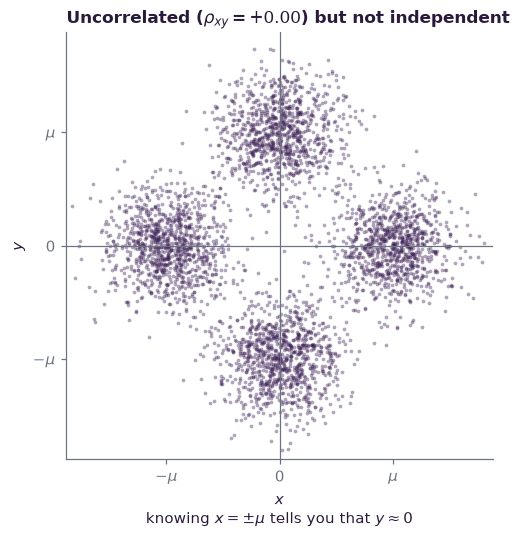

In [7]:
mu, sigma, n = 1.7, 0.45, 4000
centres = np.array([(mu, 0), (-mu, 0), (0, mu), (0, -mu)])
pts = centres[rng.integers(0, 4, n)] + rng.normal(0, sigma, (n, 2))
rho = round(np.corrcoef(pts.T)[0, 1], 2) + 0.0          # "+ 0.0" turns -0.00 into 0.00

fig, ax = plt.subplots(figsize=(4.8, 4.8), constrained_layout=True)
ax.axhline(0, color=GREY, lw=0.8)
ax.axvline(0, color=GREY, lw=0.8)
ax.scatter(*pts.T, s=6, alpha=0.4, color=PLUM, lw=0)
ticks, labels = [-mu, 0, mu], [r"$-\mu$", "0", r"$\mu$"]
ax.set(aspect="equal", xlim=(-3.2, 3.2), ylim=(-3.2, 3.2), xticks=ticks, xticklabels=labels,
       yticks=ticks, yticklabels=labels, ylabel="$y$",
       xlabel="$x$\nknowing $x = \\pm\\mu$ tells you that $y \\approx 0$")
ax.set_title(fr"Uncorrelated ($\rho_{{xy}} = {rho:+.2f}$) but not independent", loc="left")
plt.show()

### Mean, mode, median, quantiles

The **mean** is the expectation of the variable itself. The **mode** $\hat{x} = \max_x f(x)$ is where the density peaks. The **median** $\tilde{x}$ splits the probability in two halves:

$$\int_{-\infty}^{\tilde x} f(x)\,dx = \int_{\tilde x}^{\infty} f(x)\,dx = 0.5$$

The median is the least susceptible to outliers. For a symmetric distribution the three coincide; for an asymmetric one they do not, and here $\hat{x} < \tilde{x} < \bar{x}$:

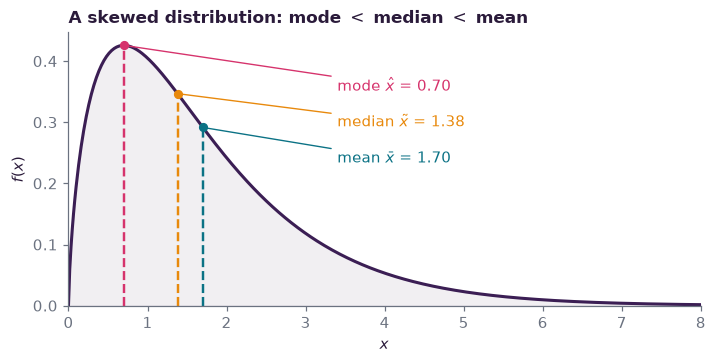

In [8]:
k = 1.7
d = stats.gamma(k)
x = np.linspace(0, 8, 500)
mode, median, mean = k - 1, d.median(), d.mean()

fig, ax = plt.subplots(figsize=(6.4, 3.2), constrained_layout=True)
ax.plot(x, d.pdf(x), color=PLUM)
ax.fill_between(x, d.pdf(x), color=PLUM, alpha=0.07)
for val, label, color, y_text in [(mode, r"mode $\hat{x}$", FUCHSIA, 0.36),
                                  (median, r"median $\tilde{x}$", AMBER, 0.30),
                                  (mean, r"mean $\bar{x}$", TEAL, 0.24)]:
    ax.vlines(val, 0, d.pdf(val), color=color, ls="--", lw=1.6)
    ax.plot(val, d.pdf(val), "o", color=color, ms=5)
    ax.annotate(f"{label} = {val:.2f}", xy=(val, d.pdf(val)), xytext=(3.4, y_text), color=color, va="center",
                arrowprops=dict(arrowstyle="-", color=color, lw=0.9))
ax.set(xlabel="$x$", ylabel="$f(x)$", ylim=(0, None), xlim=(0, 8))
ax.set_title(r"A skewed distribution: mode $<$ median $<$ mean", loc="left")
plt.show()

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Quantiles**

$$\int_{-\infty}^{q_\alpha} f(x)\,dx = \alpha = 1 - \int_{q_\alpha}^{\infty} f(x)\,dx \qquad\Longleftrightarrow\qquad q_\alpha = x : F(x) = \alpha$$

The median is the quantile $q_{0.5}$.

</div>

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**★ What to remember**

- **Two probabilities, one set of axioms.** Frequentist = long-run frequency; Bayesian = degree of belief. Pick the one that answers your question.
- **Bayes updates beliefs:** posterior $\propto$ likelihood $\times$ prior. The prior is the subjective part, and a dogma never learns.
- **A PDF is probability per unit volume.** Marginalize by integrating, condition by slicing and renormalizing.
- **Mean, variance, covariance** summarize a distribution. Mean, median and mode part ways when it is skewed.
- **Uncorrelated $\neq$ independent.**

</div>